# 02 — Can we trust this observation?

**Question:** Is a price merely recorded, or suitable for this analysis?

**By the end:** distinguish archive integrity, transport coverage, reconstruction
validity, freshness and semantic qualification. Understand why causal alignment
uses backward joins. **Time:** 30–40 minutes.

**Inputs:** operational events, clock observations, book reconstruction, BTC trades
and the published quality annotation. Quality is retrospective; it is not a signal
the historical strategy magically possessed.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    btc_grid,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import NS, Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Five different meanings of “good data”

An intact file can hold a stale quote. A connected socket can send no price. A
seeded book can be one-sided. A valid reconstruction can still lack a provider
sequence proving completeness. A reference observation can be genuine while its
relationship to settlement is unqualified.

We inspect these questions separately rather than accepting one green flag.

In [2]:
quality_fields = [
    "capture_integrity",
    "normalization_complete",
    "semantic_readiness",
    "semantic_reason",
    "closure_status",
    "settlement_readiness",
    "reconstruction_usability",
    "policy_version",
]
display(pd.Series({k: sample.quality.get(k, "NOT_REPORTED") for k in quality_fields}))
display(pd.Series(sample.quality.get("readiness", {}), name="Published readiness"))

capture_integrity                              MANIFEST_VERIFICATION_REQUIRED
normalization_complete                                                   True
semantic_readiness                                                UNSUPPORTED
semantic_reason             official_threshold_and_payoff_contract_not_att...
closure_status                                                        UNKNOWN
settlement_readiness                                              UNSUPPORTED
reconstruction_usability                                                  GAP
policy_version                                                              4
dtype: object

continuity_policy    recorded_intervals_with_explicit_unknown_provi...
policy_version                                                       2
ready                                                            False
reasons              [capture_integrity, closure_status, feed:binan...
Name: Published readiness, dtype: object

## 2. Published coverage, including gaps

The bars below are clipped to our analysis window. A covered span means what the
warehouse's policy says it means, not necessarily every venue event delivered.
For unsequenced CLOB feeds, continuity can remain unknown even inside a covered
span. Quiet reference prices and disconnected reference transport are different.

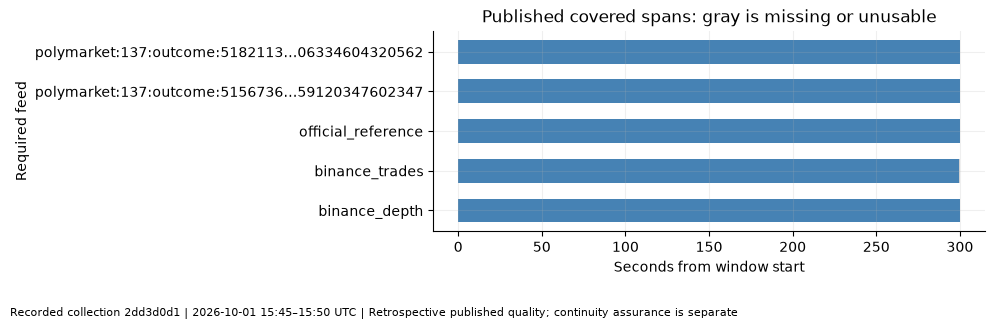

In [3]:
feeds = sample.quality.get("feeds", {})
if feeds:
    fig, ax = plt.subplots(figsize=(10, max(3, len(feeds) * 0.65)))
    names = list(feeds)
    for i, feed in enumerate(names):
        ax.broken_barh(
            [(0, (sample.end - sample.start) / NS)], (i - 0.3, 0.6), facecolors="lightgray"
        )
        spans = [
            (max(a, sample.start), min(b, sample.end)) for a, b in feeds[feed].get("intervals", [])
        ]
        spans = [((a - sample.start) / NS, (b - a) / NS) for a, b in spans if b > a]
        ax.broken_barh(spans, (i - 0.3, 0.6), facecolors="steelblue")
    ax.set_yticks(range(len(names)), [n if len(n) < 55 else n[:30] + "…" + n[-14:] for n in names])
    ax.set(
        title="Published covered spans: gray is missing or unusable",
        xlabel="Seconds from window start",
        ylabel="Required feed",
    )
    finish_plot(fig, sample, "Retrospective published quality; continuity assurance is separate")
else:
    display(Markdown("No published quality annotation exists. We do not invent coverage."))

## 3. Replay actual socket histories, then sample conservatively

The shared helper uses the existing warehouse `Books` reconstruction. REST audits
are not spliced into WebSocket books. Each connection keeps its own seed history.

Our one-second analysis grid requires a valid **two-sided** book and a last book
update no older than five seconds. Five seconds is an adjustable teaching choice,
not a claim that an illiquid book expires after five seconds. Explicit invalid
states stay visible; backward sampling does not fill across them.

,grid_points,eligible_points
label,,
Down,300,176
Up,300,176


label  valid  reason            
Down   False  crossed_book              37
              one_sided_or_empty     12907
       True   seeded                132069
Up     False  crossed_book              37
              one_sided_or_empty     12907
       True   seeded                132069
Name: Event observations, dtype: int64

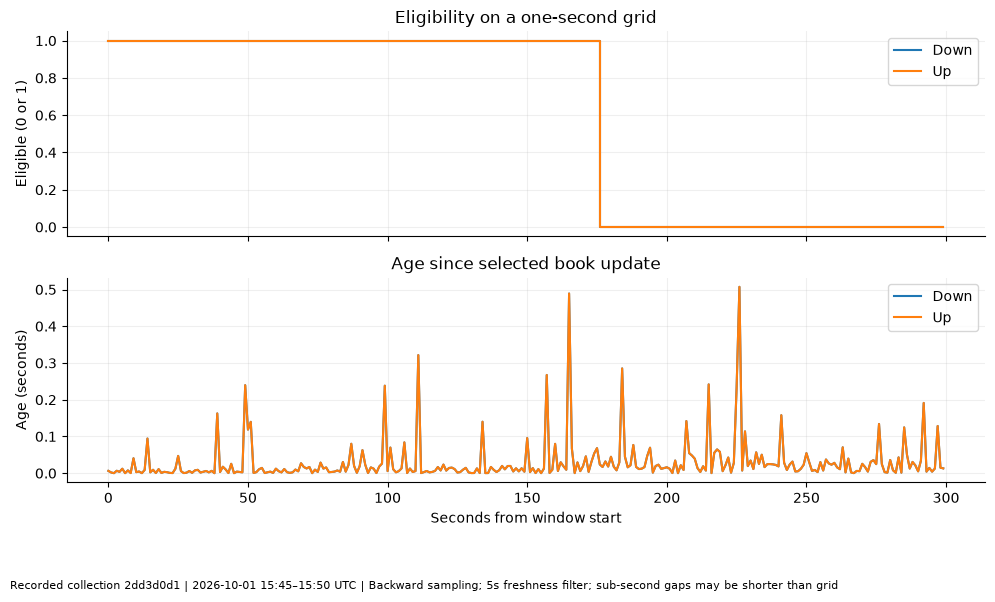

In [4]:
study = BookStudy(sample)
grid = study.grid(max_age_s=5)
display(
    grid.groupby("label").agg(
        grid_points=("time", "size"), eligible_points=("analysis_eligible", "sum")
    )
)
display(study.tape.groupby(["label", "valid", "reason"]).size().rename("Event observations"))
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for label, frame in grid.groupby("label"):
    x = (frame.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
    axes[0].step(x, frame.analysis_eligible.astype(int), where="post", label=label)
    axes[1].plot(x, frame.age_s, label=label)
axes[0].set(title="Eligibility on a one-second grid", ylabel="Eligible (0 or 1)")
axes[1].set(
    title="Age since selected book update",
    xlabel="Seconds from window start",
    ylabel="Age (seconds)",
)
for ax in axes:
    ax.legend()
finish_plot(
    fig, sample, "Backward sampling; 5s freshness filter; sub-second gaps may be shorter than grid"
)

## 4. Provider time versus arrival time

We subtract source time from local receipt time without clipping negatives. This
is an **observed clock difference**, not pure network latency: publisher timing,
clock offsets and timestamp precision all matter. Ordering across sessions also
has uncertainty. Provider times must not be silently treated as locally available.

,count,mean,std,min,25%,50%,75%,max
source_id,,,,,,,,
binance,25993.0,392.844864,128.570014,293.1217,318.1226,335.6340,412.0246,1325.3774
clob,863.0,261.249378,149.039301,185.6416,208.3486,214.8382,231.5256,1413.0213


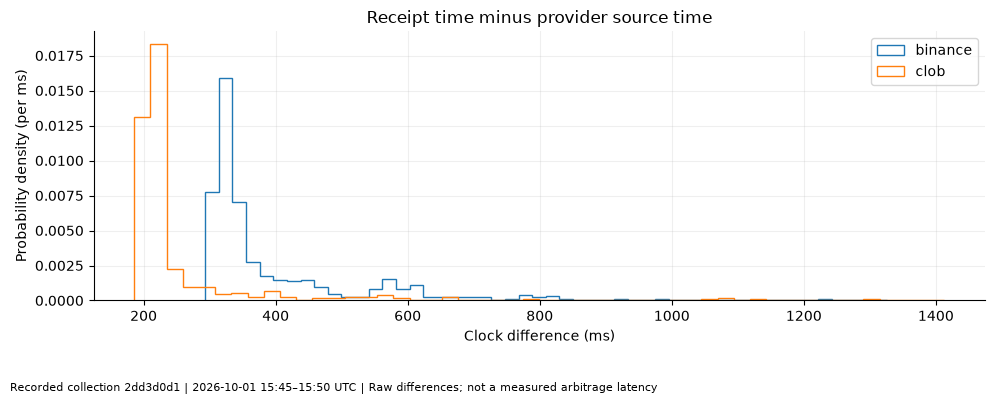

,received_at,status,rtt_ns,estimated_offset_ns,uncertainty_ns
40,2026-10-01 15:48:58.450017+00:00,OBSERVED,358500200,-127675100,179250100
41,2026-10-01 15:48:58.944221100+00:00,OBSERVED,125544700,-763411250,62772350
42,2026-10-01 15:49:59.694586+00:00,OBSERVED,363019100,-114983750,181509550


In [5]:
trades = sample.frame("trade_prints")
delay_rows = trades[trades.source_time.notna()].copy()
delay_rows["observed_difference_ms"] = (
    delay_rows.received_at - delay_rows.source_time
).dt.total_seconds() * 1000
display(delay_rows.groupby("source_id").observed_difference_ms.describe())
if not delay_rows.empty:
    fig, ax = plt.subplots()
    for source, frame in delay_rows.groupby("source_id"):
        ax.hist(frame.observed_difference_ms, bins=50, histtype="step", density=True, label=source)
    ax.set(
        title="Receipt time minus provider source time",
        xlabel="Clock difference (ms)",
        ylabel="Probability density (per ms)",
    )
    ax.legend()
    finish_plot(fig, sample, "Raw differences; not a measured arbitrage latency")
clocks = sample.frame("clock_observations")
if not clocks.empty:
    display(
        clocks[["received_at", "status", "rtt_ns", "estimated_offset_ns", "uncertainty_ns"]].tail(3)
    )

## 5. A causal join: what did we know at the decision time?

For a decision at 12:00:01, a price arriving at 12:00:01.200 is future information.
An interpolated price can accidentally use it. Backward as-of alignment only uses
arrivals at or before the decision, and we then check their age.

In [6]:
btc = btc_grid(sample)
display(btc[["time", "trade_at", "price_float", "age_s", "eligible"]].head(8))
known = btc.trade_at.notna()
assert (btc.loc[known, "trade_at"] <= btc.loc[known, "time"]).all()
known_book = grid.observation_at.notna()
assert (grid.loc[known_book, "observation_at"] <= grid.loc[known_book, "time"]).all()
print("No future observation was used by either backward join.")

,time,trade_at,price_float,age_s,eligible
0,2026-10-01 15:45:00+00:00,NaT,NaN,NaN,False
1,2026-10-01 15:45:01+00:00,2026-10-01 15:45:00.841004700+00:00,83889.44,0.158995,True
2,2026-10-01 15:45:02+00:00,2026-10-01 15:45:01.661762400+00:00,83889.43,0.338238,True
3,2026-10-01 15:45:03+00:00,2026-10-01 15:45:02.812307500+00:00,83889.44,0.187693,True
4,2026-10-01 15:45:04+00:00,2026-10-01 15:45:03.989423700+00:00,83889.44,0.010576,True
5,2026-10-01 15:45:05+00:00,2026-10-01 15:45:04.798189800+00:00,83889.43,0.201810,True
6,2026-10-01 15:45:06+00:00,2026-10-01 15:45:04.798189800+00:00,83889.43,1.201810,True
7,2026-10-01 15:45:07+00:00,2026-10-01 15:45:06.598197600+00:00,83889.44,0.401802,True


No future observation was used by either backward join.


## Exercise — change the freshness policy

Run the next cell with 1, 5 and 30 seconds. Explain which observations become
eligible and why this does not repair an invalid reconstruction.

In [7]:
freshness_comparison = []
for age in [1, 5, 30]:
    result = study.grid(max_age_s=age)
    for label, frame in result.groupby("label"):
        freshness_comparison.append(
            {
                "max_age_s": age,
                "label": label,
                "eligible_grid_fraction": frame.analysis_eligible.mean(),
            }
        )
display(pd.DataFrame(freshness_comparison))

,max_age_s,label,eligible_grid_fraction
0,1,Down,0.586667
1,1,Up,0.586667
2,5,Down,0.586667
3,5,Up,0.586667
4,30,Down,0.586667
5,30,Up,0.586667


**Suggested answer:** a wider freshness allowance permits older reconstructed
quotes. It does not turn empty, crossed, unseeded or disconnected states into usable
two-sided books, and it does not attest settlement semantics.

**Research use:** define eligibility before calculating features or performance.
**What remains unknown:** grid eligibility is not tick-perfect completeness;
event-level gaps and unknown continuity must remain part of subsequent research.

Next: [03 — One market lifecycle](03_one_market_lifecycle.ipynb).